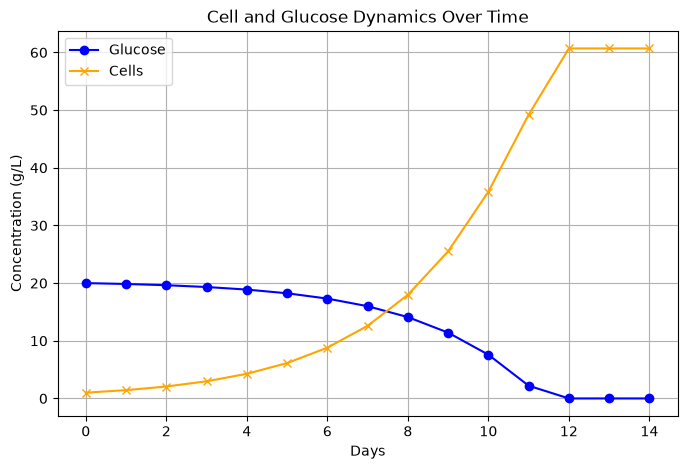

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
cells = np.empty(len(days))


# Initial conditions
glucose[0] = 20.0  # g/L
initial_cells = 1.0      # million cells/mL
cells[0] = initial_cells
glucose_consumption_rate = 0.15  # g/L per million cells per day
dt = 1.0  # time step in days

mu_max = 0.4 # g/L 
Ks = 2.0 # g/L

# Simple exponential growth model
for j in range(1, len(days)):
    mu = mu_max * glucose[j-1] / (Ks + glucose[j-1])  # Monod equation for growth rate
    cells[j] = cells[j-1] * np.exp(mu * dt)  # Cell growth
    glucose[j] = glucose[j-1] - (glucose_consumption_rate * cells[j-1] * dt)  # Glucose consumption
    if glucose[j] < 0:
        glucose[j] = 0  # Prevent negative glucose concentration

plt.figure(figsize=(8,5))
plt.plot(days, glucose, marker="o", label="Glucose", color='blue')
plt.plot(days, cells, marker="x", label="Cells", color='orange')
plt.title("Cell and Glucose Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

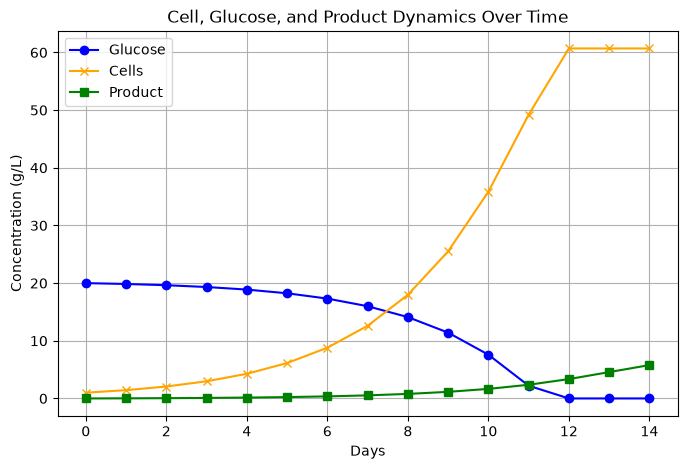

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
cells = np.empty(len(days))
product = np.empty(len(days))


# Initial conditions
glucose[0] = 20.0  # g/L
initial_cells = 1.0      # million cells/mL
cells[0] = initial_cells
product[0] = 0.0  # g/L
glucose_consumption_rate = 0.15  # g/L per million cells per day
dt = 1.0  # time step in days

mu_max = 0.4 # 1/day 
Ks = 2.0 # g/L
qp = 0.02 # g/L per million cells per day

# Simple exponential growth model
for i in range(1, len(days)):
    mu = mu_max * glucose[i-1] / (Ks + glucose[i-1])  # Monod equation for growth rate
    cells[i] = cells[i-1] * np.exp(mu * dt)  # Cell growth
    glucose[i] = glucose[i-1] - (glucose_consumption_rate * cells[i-1] * dt)  # Glucose consumption
    product[i] = product[i-1] + (qp * cells[i-1] * dt)  # Product formation
    if glucose[i] < 0:
        glucose[i] = 0  # Prevent negative glucose concentration

plt.figure(figsize=(8,5))
plt.plot(days, glucose, marker="o", label="Glucose", color='blue')
plt.plot(days, cells, marker="x", label="Cells", color='orange')
plt.plot(days, product, marker="s", label="Product", color='green')
plt.title("Cell, Glucose, and Product Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()